# Birth–death model of one EcoBici station

This notebook works in three stages:

1. **Validate**: check that the assumptions behind a birth–death chain are reasonable for your station.
2. **Compute**: build the chain and compute what it tells you (probability of empty/full, hitting times, best starting stock).
3. **Evaluate**: test the fitted model on days it has not seen.

All functions live in `ecobici_bd.py` (keep it next to this notebook).

**Running it.** With `DATA_PATH = None` the notebook generates synthetic trips whose true rates are known, so you can see how each check behaves when the model is right. To use your data, set `DATA_PATH` and `STATION` in the next cell. Cells marked *synthetic only* compare against the truth and are skipped automatically on real data.

**B · Commuter / imbalanced**

| station | name | capacity | dep_day | arr_day | net_day | net_am | net_pm |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 199 | CE-199 Anatole France-Av. Ejército N | 23 | 33.0 | 31.0 | -2.0 | 9.5 | -6.2 |
| 202 | CE-202 Calderón de la Barca-Av. Hor | 19 | 35.9 | 32.3 | -3.6 | 9.9 | -6.2 |
| 203 | CE-203 Tennyson-Av. Homero | 23 | 36.8 | 30.6 | -6.2 | 4.1 | -6.7 |
| 204 | CE-204 Temístocles-Homero | 27 | 71.6 | 49.9 | -21.7 | -19.2 | -6.3 |
| 206 | CE-206 Homero-Moliere | 23 | 98.0 | 100.1 | 2.1 | 21.2 | -9.2 |
| 207 | CE-207 Torquato Tasso-Homero | 23 | 68.0 | 74.2 | 6.2 | 20.5 | -12.1 |
| 208 | CE-208 Hesiodo-Lamartine | 25 | 248.0 | 211.8 | -36.1 | -44.0 | 1.1 |
| 210 | CE-210 Eugenio Sue-Horacio | 27 | 76.5 | 48.1 | -28.3 | -17.4 | -7.7 |
| 211 | CE-211 Isaac Newton-Horacio | 35 | 122.2 | 82.2 | -40.0 | -33.5 | -4.6 |
| 215 | CE-215 Edgar Alan Poe-Horacio | 23 | 38.5 | 34.2 | -4.3 | 8.7 | -8.0 |

In [1]:
import glob
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import ecobici_bd as bd

DATA_PATH = "../df_last_two_months.csv"  # e.g. "data/ecobici_2024_*.csv", a list of paths, or None (synthetic demo)
STATION = "215"              # id as it appears in Ciclo_Estacion_Retiro / Ciclo_EstacionArribo
CAPACITY = 23                    # official dock count if you have it (GBFS station_information); None = estimate
HOLIDAYS = []                    # treated as weekend days, e.g. ["2024-02-05", "2024-03-18"]
BURN_IN_DAYS, BURN_OUT_DAYS = 3, 2   # edges where the reconstruction is unreliable
GRID_MIN = 15                    # time grid for exposures; bin widths must be multiples of it
TEST_FRAC = 0.2                  # last 20% of days held out for Stage 3
SYNTH_DAY_SD = 0.0               # synthetic only: >0 adds day-to-day rate variation (try 0.3)

plt.rcParams.update({"figure.figsize": (10, 3.6), "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2})
C1, C2, C3, C4 = bd.COLORS

## Stage 0 — Data and occupancy reconstruction

The birth–death chain is about $N(t)$, the number of docked bikes, but the data only lists trips. Everything below needs $N(t)$, so we rebuild it first.

**Births and deaths.** For station $i$, an arrival (birth) is a trip with `Ciclo_EstacionArribo = i` at time `Fecha/Hora_Arribo`. A departure (death) is a trip with `Ciclo_Estacion_Retiro = i` at time `Fecha/Hora_Retiro`.

**Stays.** Sort each bike's trips by time. Between trip $k$ and trip $k+1$ the bike is docked somewhere:

- if trip $k$ ends at station $s$ and trip $k+1$ starts at $s$, the bike was at $s$ during $[t^{\text{in}}_k,\ t^{\text{out}}_{k+1})$;
- if trip $k+1$ starts at a different station, a truck moved it (*rebalancing*) at an unknown time inside that window.

Occupancy is then a count of covering intervals:

$$N_i(t)=\sum_b \mathbf 1\{\text{bike } b \text{ has a stay at } i \text{ covering } t\}.$$

**Truck times.** For rebalancing moves at the station we assume the *fewest truck visits* that explain the data. Each move is only known to lie inside its window $[s_j, e_j]$. Sort the windows by $e_j$. The first window's end opens a visit, and every window with $s_j \le e_j$ joins it. All members contain that point, so their common intersection $[\max s_j,\ e_j]$ is non-empty, and the visit time is placed at its midpoint (greedy interval stabbing, which is optimal for this problem).

**Capacity.** If you don't have the official dock count, $\hat C$ is the most common daily maximum of $N(t)$: a busy station hits its true capacity on many days, while reconstruction errors push the maximum above it only occasionally.

**What can go wrong.** A truck that removes a bike and later brings the same bike back, with no ride in between, is invisible: it looks like one long stay. Bikes that never move (broken) are never seen. The checks below include a direct measure of reconstruction quality: events the model says are impossible (arrivals at a full station, departures from an empty one).

In [2]:
if DATA_PATH is None:
    raw, TRUE_OCC = bd.simulate_trips(n_days=120, day_sd=SYNTH_DAY_SD, seed=1)
    STATION, SYNTH = "100", True
else:
    raw = sorted(glob.glob(DATA_PATH)) if isinstance(DATA_PATH, str) else DATA_PATH
    TRUE_OCC, SYNTH = None, False
    
df, rep = bd.load_trips(raw)

stays, moves, srep = bd.build_stays(df, STATION)
stays, unresolved = bd.enforce_capacity(stays, STATION, df.loc[df.to == STATION, "t_in"], CAPACITY)
print("arrivals still meeting a full station:", unresolved)
print({k: srep[k] for k in ("stays", "rebalancing_moves", "share_rebalanced", "overlapping_dropped")})

START = srep["data_start"].normalize() + pd.Timedelta(days=BURN_IN_DAYS)
END = srep["data_end"].normalize() - pd.Timedelta(days=BURN_OUT_DAYS)
occ_raw = bd.occupancy(stays, STATION)
C_est, daily_max = bd.estimate_capacity(occ_raw, START, END)
C = CAPACITY or C_est
print(f"capacity used C = {C}  (estimate {C_est}); daily maxima:", daily_max.to_dict())

occ = bd.clip_occupancy(occ_raw, C)
seg = bd.build_segments(occ, START, END, GRID_MIN, HOLIDAYS)
arr, dep = bd.station_events(df, STATION, occ, START, END, HOLIDAYS)
train, test = bd.chronological_split(seg.date, TEST_FRAC)
print(f"{len(arr)} arrivals, {len(dep)} departures; train {len(train)} days, test {len(test)} days")
print("impossible events (reconstruction errors): arrivals at N=C:",
      int((arr.N_before >= C).sum()), " departures at N=0:", int((dep.N_before <= 0).sum()))



arrivals still meeting a full station: 0
{'stays': 2236409, 'rebalancing_moves': 203765, 'share_rebalanced': 0.10089084389535258, 'overlapping_dropped': 0}
capacity used C = 23  (estimate 16); daily maxima: {8: 2, 9: 2, 10: 1, 11: 2, 12: 2, 13: 1, 14: 1, 15: 2, 16: 5, 17: 2, 18: 1, 19: 2, 20: 1, 21: 1, 22: 4, 23: 3}
1150 arrivals, 1269 departures; train 19 days, test 5 days
impossible events (reconstruction errors): arrivals at N=C: 0  departures at N=0: 0


In [3]:
arr_raw = bd.annotate_events(df.loc[(df.to == STATION) & (df.t_in >= START) & (df.t_in < END), "t_in"], occ_raw)
seg_raw = bd.build_segments(occ_raw, START, END, GRID_MIN, HOLIDAYS)
day = (seg_raw.minute >= 6 * 60) & (seg_raw.minute < 23 * 60)          # service hours only
ev_day = (arr_raw.minute >= 6 * 60) & (arr_raw.minute < 23 * 60)
tab = pd.DataFrame({"hours": seg_raw[day].groupby("N").dur_h.sum(),
                    "arrivals": arr_raw[ev_day].groupby("N_before").size()}).fillna(0)
tab["arrivals_per_hour"] = tab.arrivals / tab.hours
print(tab.loc[C - 4: C + 6].round(2))

    hours  arrivals  arrivals_per_hour
19  10.51      34.0               3.24
20   6.71      26.0               3.88
21   6.43      28.0               4.35
22   8.80      11.0               1.25
23   1.58       0.0               0.00


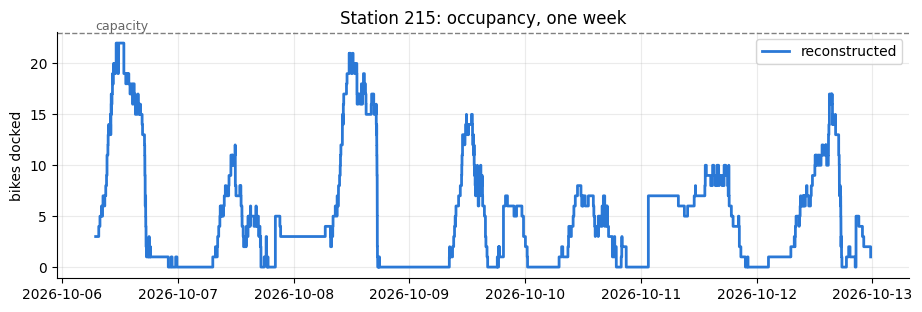

In [4]:
# Occupancy over one week (and the truth, synthetic only)
w0 = train[7]; w1 = w0 + pd.Timedelta(days=7)
o = occ[(occ.t >= w0) & (occ.t < w1)]
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.step(o.t, o.N, where="post", color=C1, label="reconstructed")
if SYNTH:
    tr = TRUE_OCC[(TRUE_OCC.t >= w0) & (TRUE_OCC.t < w1)]
    ax.step(tr.t, tr.N, where="post", color=C2, lw=1.2, alpha=0.8, label="true")
ax.axhline(C, color="0.5", lw=1, ls="--"); ax.text(o.t.iloc[0], C + 0.3, "capacity", color="0.4", fontsize=9)
ax.set_ylabel("bikes docked"); ax.set_title(f"Station {STATION}: occupancy, one week"); ax.legend(loc="upper right")
plt.show()

if SYNTH:
    ts = pd.date_range(START, END, freq="7min")
    rec, tru = bd.n_at(occ, ts), np.clip(bd.n_at(TRUE_OCC, ts), 0, C)
    by_h = pd.DataFrame({"h": ts.hour, "err": rec - tru}).groupby("h").err.mean()
    print(f"[synthetic] exact match {np.mean(rec == tru):.1%}, mean abs error {np.abs(rec - tru).mean():.2f} bikes")
    print("[synthetic] mean error by hour (+ = overcount):", by_h.round(2).to_dict())

In [5]:
st = stays[stays.station == STATION]
ev = pd.concat([pd.DataFrame({"t": st.start, "d": 1,  "kind": st.kind}),
                pd.DataFrame({"t": st.end,   "d": -1, "kind": st.kind})])
jumps = ev.groupby("t").agg(dN=("d", "sum"), kinds=("kind", lambda k: k.value_counts().to_dict()))
big = jumps[jumps.dN.abs() >= 5]
print(len(big), "instants where N changes by 5 or more")
print(big.sort_index().head(50))

# raw (unclipped) count, to see how far above 39 it really goes
print(occ_raw.N.describe())

28 instants where N changes by 5 or more
                         dN                kinds
t                                               
2026-09-22 11:12:00.000   5    {'rebal_dest': 5}
2026-09-24 12:12:31.500  10   {'rebal_dest': 10}
2026-09-24 20:58:45.000   5    {'rebal_dest': 5}
2026-09-25 15:48:29.500   5    {'rebal_dest': 5}
2026-09-25 20:44:27.500   5    {'rebal_dest': 5}
2026-09-26 12:55:43.500   5    {'rebal_dest': 5}
2026-09-28 10:57:35.500   7    {'rebal_dest': 7}
2026-09-29 21:12:09.500  10   {'rebal_dest': 10}
2026-09-30 20:08:58.000   5    {'rebal_dest': 5}
2026-10-02 21:14:42.000   5    {'rebal_dest': 5}
2026-10-05 20:28:31.500   5    {'rebal_dest': 5}
2026-10-07 20:11:30.500   5    {'rebal_dest': 5}
2026-10-09 19:30:08.000   5    {'rebal_dest': 5}
2026-10-11 01:33:17.000   7    {'rebal_dest': 7}
2026-10-12 20:37:42.500   5    {'rebal_dest': 5}
2026-10-16 19:20:30.500   5    {'rebal_dest': 5}
2026-10-19 20:02:18.500   5    {'rebal_dest': 5}
2026-10-20 19:51:51.500   5 

## Stage 1 — Validate the assumptions

### 1.1 The model and what it assumes

The state is $N(t)\in\{0,\dots,C\}$. The chain is a continuous-time Markov chain with generator

$$q_{n,n+1}=\lambda(t)\,\mathbf 1\{n<C\},\qquad q_{n,n-1}=\mu(t)\,\mathbf 1\{n>0\},\qquad q_{nn}=-\textstyle\sum_{m\neq n}q_{nm}.$$

Each assumption is something the data can contradict:

| | Assumption | What breaks it | Check |
|---|---|---|---|
| A1 | Return and pickup **demand** are Poisson processes | groups, bursts | 1.5, 1.6, 3.1 |
| A2 | Rates are constant inside each time bin | rate changes within the bin | 1.3, 1.5 |
| A3 | Rates don't depend on $n$ (except at $0$ and $C$) | app avoidance, broken last bike | 1.7 |
| A4 | One event moves one bike | friends riding together | 1.6 |
| A5 | All days of the same type share the same rates | weather, events, holidays | 1.4 |

Why Poisson? A Markov chain needs memoryless waiting times. The only memoryless continuous distribution is the exponential, and exponential gaps define a Poisson process. A good reason to expect it here: many independent riders, each rarely using this station, add up to an approximately Poisson stream (Palm–Khintchine theorem).

### 1.2 The estimator: censoring-corrected Poisson MLE

Testing assumptions requires the model fitted under them, so the estimator comes first.

Demand for pickups is Poisson with rate $\mu$, but a pickup can only happen when $N(t^-)>0$. Observed departures form a counting process with intensity $\mu\,Y(t)$, where $Y(t)=\mathbf 1\{N(t^-)>0\}$. The likelihood of a counting process with intensity $\mu Y(t)$ observed on $[0,T]$, with $k$ events, is

$$L(\mu)=\prod_{j=1}^{k}\mu\,Y(t_j)\;\exp\!\Big(-\mu\int_0^T Y(t)\,dt\Big),$$

so $\ell(\mu)=k\log\mu-\mu E$, with exposure $E=\int_0^T Y(t)\,dt$. Setting $\ell'=0$ gives

$$\hat\mu=\frac{k}{E}=\frac{\#\text{departures}}{\text{time with at least one bike}},\qquad \operatorname{SE}(\hat\mu)\approx\frac{\sqrt k}{E}.$$

The same holds for arrivals with $Y(t)=\mathbf 1\{N(t^-)<C\}$. Per bin $b$ and day type $d$, counts and exposures are summed over all days of that type. The naive estimator $k/T$ has expectation $\mu\,(1-\text{fraction of time empty})$, so it underestimates demand exactly when the station runs out. The confidence intervals are exact Poisson (Garwood) intervals:

$$\Big[\tfrac{1}{2E}\chi^2_{2k,\ \alpha/2},\ \ \tfrac{1}{2E}\chi^2_{2k+2,\ 1-\alpha/2}\Big].$$

### 1.3 Bin width (A2)

Bins are an approximation of a smoothly varying $\lambda(t)$. Narrow bins follow the curve but are noisy: relative error $\approx 1/\sqrt{k}$. Wide bins are stable but blur the peaks. Instead of guessing, fit on part of the training days and compute the **held-out log-likelihood** of the rest:

$$\ell_{\text{val}}=\sum_{j\in\text{val}}\log\hat r(t_j)\;-\;\int_{\text{val}}\hat r(t)\,Y(t)\,dt.$$

The width with the highest value predicts unseen days best.

In [6]:
arr = arr[arr.N_before < C] 
cv = bd.select_bin_width(seg, arr, dep, C, train)
print(cv.round(4))
BIN = int(cv.loglik_total.idxmax())
print("chosen bin width:", BIN, "minutes")
rates = bd.estimate_rates(seg, arr, dep, C, BIN, days=train)

             loglik_arr_per_event  loglik_dep_per_event  loglik_total
bin_minutes                                                          
15                        -0.3448                0.3699       15.8526
30                        -0.2820                0.4187       35.2770
60                        -0.2250                0.3375       28.7953
120                       -0.2251                0.3041       22.3687
180                       -0.2814                0.2742        7.6285
chosen bin width: 30 minutes


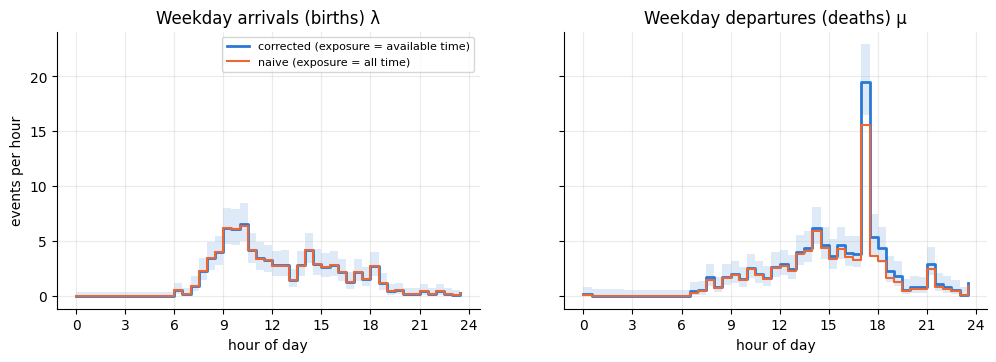

        A      D   lam  lam_naive     mu  mu_naive  frac_empty  frac_full
bin                                                                      
0     0.0    1.0  0.00       0.00   0.16      0.11        0.32       0.00
2     0.0    0.0  0.00       0.00   0.00      0.00        0.37       0.00
4     0.0    0.0  0.00       0.00   0.00      0.00        0.37       0.00
6     0.0    0.0  0.00       0.00   0.00      0.00        0.32       0.00
8     0.0    0.0  0.00       0.00   0.00      0.00        0.32       0.00
10    0.0    0.0  0.00       0.00   0.00      0.00        0.32       0.00
12    5.0    0.0  0.53       0.53   0.00      0.00        0.29       0.00
14    9.0    4.0  0.95       0.95   0.52      0.42        0.19       0.00
16   33.0    7.0  3.47       3.47   0.83      0.74        0.11       0.00
18   59.0   18.0  6.21       6.21   2.00      1.89        0.05       0.00
20   61.0   23.0  6.60       6.42   2.56      2.42        0.05       0.03
22   32.0   15.0  3.48       3.37   1.

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
truth = bd.true_binned_rates(BIN).loc["weekday"] if SYNTH else None
for ax, (col, name) in zip(axes, [("lam", "arrivals (births) λ"), ("mu", "departures (deaths) μ")]):
    r = rates.loc["weekday"]; h = r.index * BIN / 60
    ax.fill_between(h, r[f"{col}_lo"], r[f"{col}_hi"], step="post", color=C1, alpha=0.15, lw=0)
    ax.step(h, r[col], where="post", color=C1, label="corrected (exposure = available time)")
    ax.step(h, r[f"{col}_naive"], where="post", color=C2, lw=1.5, label="naive (exposure = all time)")
    if SYNTH:
        ax.step(h, truth[f"{col}_true"], where="post", color="0.25", lw=1, ls="--", label="true (synthetic)")
    ax.set_title(f"Weekday {name}"); ax.set_xlabel("hour of day"); ax.set_xticks(range(0, 25, 3))
axes[0].set_ylabel("events per hour"); axes[0].legend(fontsize=8, loc="upper right")
plt.show()
print(rates.loc["weekday"][["A", "D", "lam", "lam_naive", "mu", "mu_naive", "frac_empty", "frac_full"]].round(2).iloc[::max(1, 60 // BIN)])

### 1.4 Do days of the same type share a rate? (A5)

Under the model, the count on day $j$ in bin $b$ is $k_j\sim\text{Poisson}(r_b E_j)$, where $E_j$ is that day's available time in the bin. The Pearson statistic

$$X^2_b=\sum_{j}\frac{(k_j-\hat r_b E_j)^2}{\hat r_b E_j}\ \sim\ \chi^2_{J-1}\quad\text{under }H_0$$

compares the observed spread across days with the Poisson spread. The dispersion ratio $\varphi=X^2/\text{df}$ is $\approx1$ under $H_0$. With $\varphi>1$, days really differ (weather, events), and the counts follow a mixture. If the daily level is $\Lambda_d\sim\text{Gamma}(\alpha,\alpha)$, the counts are negative binomial with $\operatorname{Var}=\text{mean}+\text{mean}^2/\alpha$.

Day-bins where the station was available for less than half the bin are dropped. Their expected counts are tiny, which makes single Pearson terms explode even when the model is right. Results are pooled over bins by adding the $X^2$ and the df.

In [8]:
res_between = {k: bd.between_day_dispersion(seg, ev, rates, k, C, days=train) for k, ev in (("arr", arr), ("dep", dep))}
for k, r in res_between.items():
    print(k, {a: round(float(b), 3) for a, b in bd.pooled(r).items()})

arr {'X2': 524.571, 'df': 463.0, 'phi': 1.133, 'p': 0.025, 'bins': 26.0, 'share_bins_p<0.05': 0.115}
dep {'X2': 585.025, 'df': 462.0, 'phi': 1.266, 'p': 0.0, 'bins': 30.0, 'share_bins_p<0.05': 0.2}


### 1.5 Is the process Poisson inside a bin? (A1, A2)

This test separates *within-day* behaviour from the day-level variation in 1.4. Condition on the total $K$ in one (day, bin). If events are Poisson with a constant rate inside the bin, then given $K$ they fall into the sub-slots $u$ **multinomially**, with probabilities proportional to available time:

$$(k_u)_u\,\big|\,K\ \sim\ \text{Multinomial}\Big(K,\ \tfrac{E_u}{\sum_v E_v}\Big),\qquad X^2=\sum_u\frac{(k_u-K\,w_u)^2}{K\,w_u}\ \sim\ \chi^2_{m-1}.$$

The daily level cancels out in the conditioning, so day-to-day variation can't trigger this test. Values $\varphi>1$ mean events bunch up inside the bin: either the rate changes within the bin (bins too wide, see 1.3) or the events are clustered (1.6).

In [9]:
SUB = GRID_MIN if BIN > GRID_MIN else None
res_within = {}
if SUB:
    res_within = {k: bd.within_bin_dispersion(seg, ev, k, C, BIN, SUB, days=train) for k, ev in (("arr", arr), ("dep", dep))}
    for k, r in res_within.items():
        print(k, {a: round(float(b), 3) for a, b in bd.pooled(r).items()})
else:
    print("bin width equals the grid; rebuild segments with a finer GRID_MIN to run this test")

arr {'X2': 356.929, 'df': 354.0, 'phi': 1.008, 'p': 0.446, 'bins': 36.0, 'share_bins_p<0.05': 0.0}
dep {'X2': 411.703, 'df': 341.0, 'phi': 1.207, 'p': 0.005, 'bins': 36.0, 'share_bins_p<0.05': 0.083}


### 1.6 Do bikes move in groups? (A4)

Under a Poisson process with local rate $r$, the chance that an event follows the previous one within $w$ seconds is $1-e^{-rw}$. Adding over events gives the expected number of short gaps:

$$\mathbb E[\#\{\text{gaps}<w\}]=\sum_j\big(1-e^{-r(t_j)\,w}\big).$$

If the observed count is much higher (ratio > 1, small p-value), people arrive or leave together. The fix is a compound Poisson model, where each event moves a random number of bikes. That is still a Markov chain, with extra off-diagonal entries in $Q$.

In [10]:
res_clu = {k: bd.clustering_check(ev[ev.date.isin(train)], rates, k, window_s=60) for k, ev in (("arr", arr), ("dep", dep))}
for k, r in res_clu.items():
    print(k, {a: (round(b, 3) if isinstance(b, float) else b) for a, b in r.items()})

arr {'window_s': 60, 'observed_short_gaps': 51, 'expected_short_gaps': 43.248, 'ratio': 1.179, 'p_excess': 0.136}
dep {'window_s': 60, 'observed_short_gaps': 112, 'expected_short_gaps': 78.667, 'ratio': 1.424, 'p_excess': 0.0}


### 1.7 Do rates depend on the state? (A3)

Group the states by bikes available (for departures) or free docks (for arrivals), e.g. $\{1\},\{2\},\{3,4\},\{5\ldots9\},\{10+\}$. Compare two multiplicative Poisson models for counts $k$ with exposure $E$ in each (cell, group, day):

$$H_0:\ r=a_{\text{cell}}\qquad\text{vs}\qquad H_1:\ r=a_{\text{cell}}\,b_{\text{group}},\qquad \text{LR}=2(\ell_1-\ell_0)\sim\chi^2_{G-1}.$$

Both are fitted exactly by iterative proportional fitting: each factor is rescaled until its fitted total equals its observed total, which is the Poisson MLE for a log-linear model. The table shows observed/expected events per group under $H_0$. A flat profile of $\approx1$ supports A3.

**Two traps.**
1. *Busy days.* Busy days also empty the station, so day-level variation looks like state dependence. A free effect per date does **not** fix this, because $n$ is driven by the same day's earlier events and fixed-effect Poisson is then biased. Instead, the exposures are scaled by an **outside** measure of the day's busyness, system-wide trips that day relative to the mean for that day type.
2. *Phantom bikes.* Reconstruction errors leave bikes in the count that aren't really there. That shows up as a drop **only** in the "1 bike" group (the station was truly empty). Genuine avoidance (riders reading the app) shows up as a gradual decline over 1, 2, 3–4. A broken last bike, which is common in practice, also looks like a drop at 1. So the robustness check repeats the test starting at 2 bikes.

In [13]:
scale = bd.system_day_scale(df, HOLIDAYS)
res_state = {}
for k, ev in (("arr", arr), ("dep", dep)):
    res_state[k] = bd.state_dependence_test(seg, ev, k, C, BIN, days=train, day_scale=scale)
    rob = bd.state_dependence_test(seg, ev, k, C, BIN, days=train, edges=(2, 3, 5, 10), day_scale=scale)
    res_state[k]["p_from2"] = rob["p"]
    print(f"{k}: LR={res_state[k]['LR']:.1f}, df={res_state[k]['df']}, p={res_state[k]['p']:.4f}   "
          f"| starting at 2: p={rob['p']:.4f}")
    print(res_state[k]["table"].round(3), "\n")

arr: LR=4.5, df=4, p=0.3373   | starting at 2: p=0.7645
     events  expected_H0  exposure_h  obs/exp
grp                                          
1      11.0       17.868       5.645    0.616
2      20.0       15.598       4.813    1.282
3-4    48.0       47.679      16.289    1.007
5-9   170.0      164.204      50.194    1.035
10+   488.0      491.651     372.030    0.993 

dep: LR=83.5, df=4, p=0.0000   | starting at 2: p=0.0621
     events  expected_H0  exposure_h  obs/exp
grp                                          
1      27.0       87.980      62.183    0.307
2      54.0       54.189      49.448    0.997
3-4   109.0       87.026      63.196    1.252
5-9   198.0      164.253      75.242    1.205
10+   436.0      430.552     113.407    1.013 



### 1.8 Verdict

A rule of thumb for each check. A tiny p-value with an effect close to 1 (e.g. $\varphi=1.03$ on 10,000 events) is statistically significant but practically harmless. Judge by the size of the effect, not only by $p$.

In [12]:
def verdict():
    rows = []
    for k in ("arr", "dep"):
        b = bd.pooled(res_between[k])
        rows.append((f"A5 days share rates ({k})", f"phi={b['phi']:.2f}, p={b['p']:.3g}",
                     "OK" if b["phi"] < 1.1 or b["p"] > 0.01 else "VIOLATED -> random daily level (Cox)"))
        if res_within:
            w = bd.pooled(res_within[k])
            rows.append((f"A1/A2 Poisson within bin ({k})", f"phi={w['phi']:.2f}, p={w['p']:.3g}",
                         "OK" if w["phi"] < 1.1 or w["p"] > 0.01 else "VIOLATED -> narrower bins or clustering"))
        c = res_clu[k]
        rows.append((f"A4 single moves ({k})", f"obs/exp={c['ratio']:.2f}, p={c['p_excess']:.3g}",
                     "OK" if c["ratio"] < 1.2 or c["p_excess"] > 0.01 else "VIOLATED -> batch (compound) arrivals"))
        s = res_state[k]; oe = s["table"]["obs/exp"]
        ok_all = s["p"] > 0.01 or (oe - 1).abs().max() < 0.1
        ok_from2 = s["p_from2"] > 0.01
        rows.append((f"A3 no state dependence ({k})",
                     f"p={s['p']:.3g} (from 2 bikes: {s['p_from2']:.3g}), obs/exp {oe.min():.2f}-{oe.max():.2f}",
                     "OK" if ok_all else ("OK from n>=2; drop at n=1 = phantom or broken last bike (1.7)" if ok_from2
                                          else "VIOLATED -> state-dependent rates")))
    return pd.DataFrame(rows, columns=["assumption", "evidence", "verdict"])
pd.set_option("display.max_colwidth", 80); verdict()

,assumption,evidence,verdict
0,A5 days share rates (arr),"phi=1.13, p=0.0249",OK
1,A1/A2 Poisson within bin (arr),"phi=1.01, p=0.446",OK
2,A4 single moves (arr),"obs/exp=1.18, p=0.136",OK
3,A3 no state dependence (arr),"p=0.337 (from 2 bikes: 0.764), obs/exp 0.62-1.28",OK
4,A5 days share rates (dep),"phi=1.27, p=8.61e-05",VIOLATED -> random daily level (Cox)
5,A1/A2 Poisson within bin (dep),"phi=1.21, p=0.00516",VIOLATED -> narrower bins or clustering
6,A4 single moves (dep),"obs/exp=1.42, p=0.000234",VIOLATED -> batch (compound) arrivals
7,A3 no state dependence (dep),"p=3.21e-17 (from 2 bikes: 0.0621), obs/exp 0.31-1.25",OK from n>=2; drop at n=1 = phantom or broken last bike (1.7)


## Stage 2 — Compute the process

### 2.0 Truck visits as jump matrices

Rider dynamics stay in $Q$. A scheduled truck visit at time $\tau$ is an instantaneous jump

$$\mathbf p(\tau^+) = \mathbf p(\tau^-)\,T,$$

where $T_{\text{drop}}=(1-p_{\text{visit}})I+p_{\text{visit}}\sum_k w_k S^+_k$ shifts $n\to\min(n+k,C)$ and $T_{\text{remove}}=(1-p_{\text{visit}})I+p_{\text{visit}}\sum_k w_k S^-_k$ shifts $n\to\max(n-k,0)$.

From training days only, we group `rebal_dest` stays by `start` (drop-offs) and `rebal_origin` stays by `end` (removals), keeping groups of size $\ge 5$. **Inspect the histogram of group times per station** before choosing windows — do not hard-code windows across stations.

In [ ]:
# Inspect the histogram of truck group times (sizes >= 5) on training days
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2), sharey=True)
for ax, (kind, st_kind, tcol) in zip(
    axes, [("Drop-offs (rebal_dest)", "rebal_dest", "start"),
           ("Removals (rebal_origin)", "rebal_origin", "end")]
):
    st_k = stays[(stays.station == STATION) & (stays.kind == st_kind)]
    g = st_k.groupby(tcol).size()
    g = g[g >= 5]
    if not g.empty:
        t = pd.Series(g.index)
        in_train = t.dt.normalize().isin(train).values
        for dt_name, alpha in (("weekday", 0.75), ("weekend", 0.35)):
            m = in_train & (bd.daytype_of(t.dt.normalize(), HOLIDAYS) == dt_name)
            hrs = (t[m].dt.hour + t[m].dt.minute / 60).values
            if len(hrs):
                ax.hist(hrs, bins=range(0, 25), alpha=alpha, label=f"{dt_name} ({len(hrs)} visits)")
    ax.set_title(f"Station {STATION}: {kind}, size >= 5"); ax.set_xlabel("hour of day")
    ax.set_xticks(range(0, 25, 3)); ax.legend(fontsize=8)
axes[0].set_ylabel("truck visits (train)")
plt.tight_layout(); plt.show()

# Windows chosen from the histogram above (adjust per station!)
trucks = [
    bd.estimate_truck_event(stays, STATION, C, train, BIN, kind="drop",   daytype="weekday", hours=(18, 22)),
    bd.estimate_truck_event(stays, STATION, C, train, BIN, kind="drop",   daytype="weekday", hours=(8, 12)),
    bd.estimate_truck_event(stays, STATION, C, train, BIN, kind="remove", daytype="weekday", hours=(16, 21)),
]
trucks = [t for t in trucks if t]
for ev in trucks:
    print(f"{ev['kind']} ({ev['daytype']}, {ev['hours']}): p_visit={ev['p_visit']:.2f}, "
          f"tau={ev['tau_h']:.2f}h (edge {ev['edge']}), sizes={ev['sizes'].tolist()}, probs={np.round(ev['probs'], 2).tolist()}")

### 2.1 Transient distribution (Kolmogorov forward equations)

Let $p_n(t)=P(N(t)=n)$ as a row vector $\mathbf p(t)$. Balancing what enters and leaves state $n$ during $[t,t+h]$ and letting $h\to0$:

$$\frac{dp_n}{dt}=\lambda_{n-1}p_{n-1}-(\lambda_n+\mu_n)p_n+\mu_{n+1}p_{n+1}\quad\Longleftrightarrow\quad \frac{d\mathbf p}{dt}=\mathbf p(t)\,Q(t).$$

With $Q$ constant on each bin of length $\Delta$ hours, the solution is a product of matrix exponentials, **ordered** earliest first because matrices don't commute, with truck jump matrices $T$ applied at their bin edges:

$$\mathbf p(t_0+m\Delta)=\mathbf p(t_0)\,e^{Q_{b_0}\Delta}\,e^{Q_{b_0+1}\Delta}\cdots e^{Q_{b_0+m-1}\Delta}.$$

The time unit of $Q$ and $\Delta$ must match. Rates are per hour here, so a 30-minute bin uses $\Delta=0.5$. Inside a bin we take several sub-steps so the curves are smooth. That changes only the plotting resolution, not the result.

The starting state is the median occupancy observed at 05:00 on training weekdays.

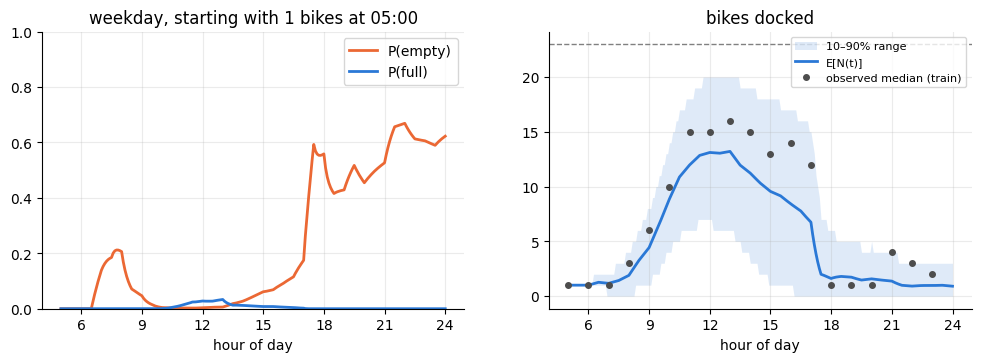

In [14]:
DT = "weekday"
wk = train[bd.daytype_of(train, HOLIDAYS) == DT]
n0 = int(np.median(bd.n_at(occ, wk + pd.Timedelta(hours=5))))
ts_base, ps_base = bd.day_profile(rates, DT, C, n0, start_h=5, end_h=24, substeps=6)
ts, ps = bd.day_profile(rates, DT, C, n0, start_h=5, end_h=24, substeps=6, trucks=trucks)
cdf = ps.cumsum(1); mean = ps @ np.arange(C + 1)
mean_base = ps_base @ np.arange(C + 1)
q10, q90 = (cdf >= 0.1).argmax(1), (cdf >= 0.9).argmax(1)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].plot(ts, ps[:, 0], color=C2, label="P(empty) + trucks")
axes[0].plot(ts_base, ps_base[:, 0], color=C2, lw=1.2, ls="--", alpha=0.6, label="P(empty) rider-only")
axes[0].plot(ts, ps[:, C], color=C1, label="P(full) + trucks")
axes[0].set_ylim(0, 1); axes[0].set_title(f"{DT}, starting with {n0} bikes at 05:00"); axes[0].legend(fontsize=8)
axes[1].fill_between(ts, q10, q90, color=C1, alpha=0.15, lw=0, label="10–90% range")
axes[1].plot(ts, mean, color=C1, label="E[N(t)] + trucks")
axes[1].plot(ts_base, mean_base, color=C1, lw=1.2, ls="--", alpha=0.6, label="E[N(t)] rider-only")
obs = np.array([bd.n_at(occ, wk + pd.Timedelta(hours=h)) for h in range(5, 24)])
axes[1].plot(range(5, 24), np.median(obs, 1), "o", color="0.3", ms=4, label="observed median (train)")
axes[1].axhline(C, color="0.5", lw=1, ls="--"); axes[1].set_title("bikes docked"); axes[1].legend(fontsize=8)
for ax in axes: ax.set_xlabel("hour of day"); ax.set_xticks(range(6, 25, 3))
plt.show()

### 2.2 Stationary law and whether it applies

If the rates stayed fixed, detailed balance across the cut between $n$ and $n+1$, $\pi_n\lambda=\pi_{n+1}\mu$, gives a truncated geometric law with $\rho=\lambda/\mu$:

$$\pi_n=\frac{(1-\rho)\rho^n}{1-\rho^{C+1}}\ (\rho\ne1),\qquad \pi_n=\tfrac{1}{C+1}\ (\rho=1).$$

That only describes a bin if the chain forgets its start within the bin. The eigenvalues of $-Q$ for this chain are $0$ and

$$\gamma_k=\lambda+\mu-2\sqrt{\lambda\mu}\cos\!\Big(\tfrac{k\pi}{C+1}\Big),\quad k=1,\dots,C,$$

so the **relaxation time** is $1/\gamma_1$. When it is longer than the bin, the stationary law is the wrong tool, and the transient computation of 2.1 is the one to use. The table below checks this for each bin.

In [15]:
lam_b, mu_b = bd.bin_rates(rates, DT)
tab = pd.DataFrame({"hour": np.arange(len(lam_b)) * BIN / 60, "lam": lam_b, "mu": mu_b})
tab["rho"] = tab.lam / tab.mu.replace(0, np.nan)
pis = [bd.stationary(l, m, C) for l, m in zip(lam_b, mu_b)]
tab["pi_empty"] = [p[0] for p in pis]; tab["pi_full"] = [p[C] for p in pis]
tab["relax_h"] = 1 / np.array([bd.spectral_gap(l, m, C) for l, m in zip(lam_b, mu_b)])
tab["stationary_ok"] = tab.relax_h < BIN / 60
print(tab.iloc[::max(1, 60 // BIN)].round(3).to_string(index=False))

# check the closed forms against linear algebra for one busy bin
b = int(np.argmax(mu_b)); Q = bd.generator(lam_b[b], mu_b[b], C)
print("\ncheck at bin", b, ": |pi Q| =", np.abs(bd.stationary(lam_b[b], mu_b[b], C) @ Q).max(),
      "; gap closed form vs eig:", bd.spectral_gap(lam_b[b], mu_b[b], C), np.sort(np.linalg.eigvals(-Q).real)[1])

 hour   lam     mu   rho  pi_empty  pi_full  relax_h  stationary_ok
  0.0 0.000  0.156 0.000     1.000    0.000    6.430          False
  1.0 0.000  0.000   NaN       NaN      NaN      inf          False
  2.0 0.000  0.000   NaN       NaN      NaN      inf          False
  3.0 0.000  0.000   NaN       NaN      NaN      inf          False
  4.0 0.000  0.000   NaN       NaN      NaN      inf          False
  5.0 0.000  0.000   NaN       NaN      NaN      inf          False
  6.0 0.526  0.000   NaN     0.000    1.000    1.900          False
  7.0 0.947  0.520 1.823     0.000    0.452   13.199          False
  8.0 3.474  0.831 4.181     0.000    0.761    1.068          False
  9.0 6.211  2.000 3.105     0.000    0.678    0.818          False
 10.0 6.601  2.556 2.583     0.000    0.613    0.988          False
 11.0 3.478  1.667 2.087     0.000    0.521    2.699          False
 12.0 2.819  2.889 0.976     0.054    0.031   20.302          False
 13.0 1.477  4.000 0.369     0.631    0.000    1

C:\Users\axely\AppData\Local\Temp\ipykernel_23820\3615462415.py:6: RuntimeWarning: divide by zero encountered in divide
  tab["relax_h"] = 1 / np.array([bd.spectral_gap(l, m, C) for l, m in zip(lam_b, mu_b)])


### 2.3 Expected time until the station empties or fills

Let $T_n$ be the expected time to reach $0$ from $n$, with constant rates. **First-step analysis**: the chain waits on average $1/(\lambda_n+\mu_n)$ and then jumps,

$$T_n=\frac{1}{\lambda_n+\mu_n}+\frac{\lambda_n}{\lambda_n+\mu_n}T_{n+1}+\frac{\mu_n}{\lambda_n+\mu_n}T_{n-1},\qquad T_0=0,\quad T_C=\tfrac1\mu+T_{C-1}.$$

With increments $u_n=T_n-T_{n-1}$, this becomes $u_C=1/\mu$ and $u_n=(1+\lambda u_{n+1})/\mu$, which unrolls to

$$u_n=\frac1\mu\sum_{k=0}^{C-n}\rho^k,\qquad T_n=\sum_{m=1}^n u_m.$$

The time to fill is the mirror image ($n\to C-n$, $\lambda\leftrightarrow\mu$). The cell computes time-to-empty at the pickup peak and time-to-full at the return peak, and checks them against a direct linear solve of $Q_{-0,-0}\,T=-\mathbf 1$.

In [16]:
b_dep, b_arr = int(np.argmax(mu_b)), int(np.argmax(lam_b))
T_empty = bd.hitting_time_empty(lam_b[b_dep], mu_b[b_dep], C)
T_full = bd.hitting_time_full(lam_b[b_arr], mu_b[b_arr], C)
print(f"time to EMPTY uses the pickup peak ({b_dep * BIN / 60:.1f}h: lam={lam_b[b_dep]:.2f}, mu={mu_b[b_dep]:.2f} per hour)")
print(f"time to FULL  uses the return peak ({b_arr * BIN / 60:.1f}h: lam={lam_b[b_arr]:.2f}, mu={mu_b[b_arr]:.2f} per hour)")
print("max |closed form - linear solve|:",
      np.abs(T_empty - bd.hitting_time_linear(lam_b[b_dep], mu_b[b_dep], C, 0)).max(),
      np.abs(T_full - bd.hitting_time_linear(lam_b[b_arr], mu_b[b_arr], C, C)).max())
print(pd.DataFrame({"n": range(C + 1), "hours_to_empty": T_empty, "hours_to_full": T_full}).iloc[::2].round(2).to_string(index=False))
print("(these assume the peak rates last; read them as 'how fast it drains/fills at the peak')")

time to EMPTY uses the pickup peak (17.0h: lam=2.21, mu=19.51 per hour)
time to FULL  uses the return peak (10.0h: lam=6.60, mu=2.56 per hour)
max |closed form - linear solve|: 8.881784197001252e-16 7.993605777301127e-15
 n  hours_to_empty  hours_to_full
 0            0.00           5.53
 2            0.12           5.17
 4            0.23           4.69
 6            0.35           4.20
 8            0.46           3.71
10            0.58           3.21
12            0.69           2.72
14            0.81           2.22
16            0.92           1.73
18            1.04           1.24
20            1.16           0.74
22            1.27           0.25
(these assume the peak rates last; read them as 'how fast it drains/fills at the peak')


### 2.4 Best starting stock

Expected lost customers between $t_0$ and $t_1$, starting with $n_0$ bikes:

$$J(n_0)=\int_{t_0}^{t_1}\Big(\mu(t)\,p_0(t)+\lambda(t)\,p_C(t)\Big)dt,\qquad \mathbf p(t_0)=e_{n_0}^{\top}.$$

On a bin of length $\Delta$ with constant $Q$, the integral $\int_0^\Delta e^{Qs}ds$ comes exactly from one matrix exponential (Van Loan):

$$\exp\!\begin{pmatrix}Q\Delta & I\Delta\\ 0 & 0\end{pmatrix}=\begin{pmatrix}e^{Q\Delta} & \int_0^\Delta e^{Qs}ds\\ 0 & I\end{pmatrix}.$$

Using the whole transition matrix in place of one $\mathbf p$ gives $J(n_0)$ for **every** $n_0$ in a single pass:

$$\mathbf J=\sum_b \Phi_b\Big(\int_0^\Delta e^{Q_b s}ds\Big)\mathbf c_b,\qquad \Phi_b=\prod_{k<b}e^{Q_k\Delta},\quad \mathbf c_b=(\mu_b,0,\dots,0,\lambda_b)^\top.$$

This is the calculation behind a rebalancing target: the stock the trucks should leave before service starts.

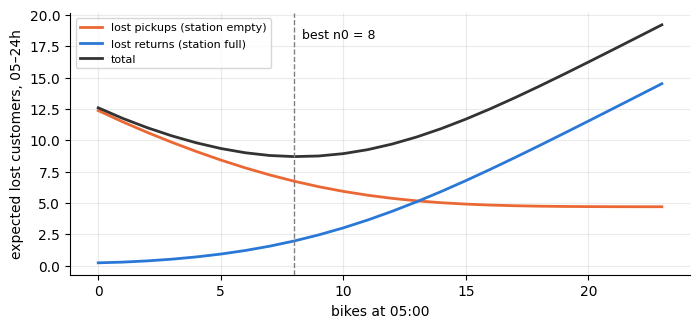

    lost_pickups  lost_returns  hours_empty  hours_full  lost_total
n0                                                                 
0          12.37          0.22         6.59        0.08       12.59
2          10.63          0.38         4.01        0.13       11.01
4           9.11          0.69         3.60        0.22        9.80
6           7.80          1.21         3.30        0.37        9.00
8           6.73          1.97         3.04        0.58        8.70
10          5.92          3.01         2.84        0.85        8.93
12          5.36          4.34         2.70        1.15        9.70
14          5.02          5.91         2.61        1.48       10.93
16          4.83          7.68         2.55        1.83       12.51
18          4.74          9.57         2.53        2.20       14.32
20          4.71         11.53         2.52        2.64       16.24
22          4.70         13.52         2.52        3.47       18.22


In [17]:
L_rider = bd.losses_by_start_stock(rates, DT, C, start_h=5, end_h=24)
L = bd.losses_by_start_stock(rates, DT, C, start_h=5, end_h=24, trucks=trucks)
best = int(L.lost_total.idxmin())
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(L.index, L.lost_pickups, color=C2, label="lost pickups (station empty)")
ax.plot(L.index, L.lost_returns, color=C1, label="lost returns (station full)")
ax.plot(L.index, L.lost_total, color="0.2", label="total (+ trucks)")
ax.plot(L_rider.index, L_rider.lost_total, color="0.5", lw=1.2, ls="--", label="total (rider-only)")
ax.axvline(best, color="0.5", lw=1, ls="--"); ax.text(best + 0.3, ax.get_ylim()[1] * 0.9, f"best n0 = {best}", fontsize=9)
ax.set_xlabel("bikes at 05:00"); ax.set_ylabel("expected lost customers, 05–24h"); ax.legend(fontsize=8)
plt.show()
print(L.round(2).iloc[::2])

### 2.5 Checking the computations

The matrix exponentials are verified by simulating the same chain directly (Gillespie): in state $n$, wait $\text{Exp}(\lambda_n+\mu_n)$, then move up with probability $\lambda_n/(\lambda_n+\mu_n)$. When a wait crosses a bin edge, restart the clock at the edge. That is exact because of memorylessness. The Monte Carlo frequencies should match the exact probabilities up to sampling noise ($\approx\sqrt{p(1-p)/R}$).

In [18]:
rng = np.random.default_rng(0); R = 3000; grid = np.array([8, 9, 12, 18, 19, 21.0])
hits = np.zeros((len(grid), C + 1)); hours_empty = []
for _ in range(R):
    tt, nn = bd.simulate_ctmc(rates, DT, C, n0, 5, 24, rng, trucks=trucks)
    hits[np.arange(len(grid)), nn[np.searchsorted(tt, grid, side="right") - 1]] += 1
    hours_empty.append(np.diff(np.r_[tt, 24])[nn == 0].sum())
hits /= R
for g, h in zip(grid, hits):
    k = np.argmin(np.abs(ts - g))
    print(f"t={g:>4}: P(empty) exact {ps[k, 0]:.3f}  MC {h[0]:.3f} | P(full) exact {ps[k, C]:.3f}  MC {h[C]:.3f}")
print(f"hours empty from n0={n0}: exact {L.hours_empty[n0]:.3f}, MC {np.mean(hours_empty):.3f} ± {np.std(hours_empty) / np.sqrt(R):.3f}")

t= 8.0: P(empty) exact 0.206  MC 0.205 | P(full) exact 0.000  MC 0.000
t= 9.0: P(empty) exact 0.047  MC 0.044 | P(full) exact 0.000  MC 0.000
t=12.0: P(empty) exact 0.003  MC 0.004 | P(full) exact 0.028  MC 0.028
t=18.0: P(empty) exact 0.559  MC 0.570 | P(full) exact 0.000  MC 0.000
t=19.0: P(empty) exact 0.429  MC 0.448 | P(full) exact 0.000  MC 0.000
t=21.0: P(empty) exact 0.526  MC 0.534 | P(full) exact 0.000  MC 0.000
hours empty from n0=1: exact 4.357, MC 4.416 ± 0.043


### 2.6 Historical losses

If $\hat\lambda$ and $\hat\mu$ were the true demand rates, how many riders were turned away on the observed days? Unlike Stage 2.4 (expected losses from a modeled starting stock), this integrates $\hat\mu(t)\mathbf 1\{N(t)=0\}$ and $\hat\lambda(t)\mathbf 1\{N(t)=C\}$ over the **real** reconstructed occupancy history `seg`:

$$\text{lost share (pickups)} = \frac{\text{lost pickups}}{\text{lost pickups} + \text{observed departures}}.$$

**Cautions.** Phantom bikes make reconstructed $N \ge N_{\text{true}}$, undercounting empty time (lost pickups biased low) and overcounting full time (lost returns biased high, partly corrected by `enforce_capacity`). Compare with Stage 2.4 at $n_0$: large differences point to truck visits present in history.

In [ ]:
per_day, summary, by_hour = bd.historical_losses(seg, rates, C, dep=dep, arr=arr, days=train)
hist_summary = summary
print(summary.round(2))
print("\nWeekday average per day by clock hour:")
print(by_hour.loc["weekday"].round(2))
if DT in summary.index:
    print(f"\nCompare {DT} historical mean vs Stage 2.4 at n0={n0}:")
    print(f"  Historical: lost_pickups={summary.loc[DT, ('lost_pickups', 'mean')]:.2f}, lost_returns={summary.loc[DT, ('lost_returns', 'mean')]:.2f}, hours_empty={summary.loc[DT, ('hours_empty', 'mean')]:.2f}")
    print(f"  Stage 2.4 (rider-only): lost_pickups={L_rider.loc[n0, 'lost_pickups']:.2f}, lost_returns={L_rider.loc[n0, 'lost_returns']:.2f}, hours_empty={L_rider.loc[n0, 'hours_empty']:.2f}")
    print(f"  Stage 2.4 (+trucks):    lost_pickups={L.loc[n0, 'lost_pickups']:.2f}, lost_returns={L.loc[n0, 'lost_returns']:.2f}, hours_empty={L.loc[n0, 'hours_empty']:.2f}")

## Stage 3 — Evaluate on held-out days

The model was fitted on the first 80% of days. Everything here uses only the last 20%.

### 3.1 Time-rescaling test

Define the compensator $\Lambda(t)=\int_0^t \hat r(s)\,Y(s)\,ds$. The **time-rescaling theorem** says that if $\hat r(t)Y(t)$ is the true intensity, the rescaled gaps

$$z_j=\Lambda(t_j)-\Lambda(t_{j-1})\ \stackrel{\text{iid}}{\sim}\ \text{Exp}(1).$$

This checks the whole model at once: rates, bins, censoring and Poisson-ness. The diagnostics:

- **KS test** of $z$ against Exp(1). The p-value is valid because the rates come from other days.
- **QQ plot.** Too many small $z$ means clustering. A bend in the middle means the rate shape is wrong.
- **Lag-1 correlation of $z$**, about $0\pm 1/\sqrt n$ under $H_0$. A positive correlation means busy periods last longer than the model allows, which is the signature of day-level variation (A5).

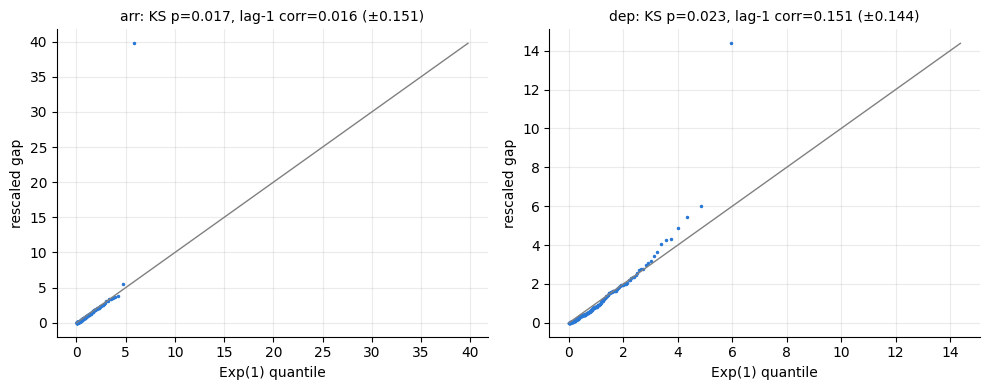

In [19]:
tr = {k: bd.time_rescaling(seg, ev, rates, k, C, test) for k, ev in (("arr", arr), ("dep", dep))}
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (k, r) in zip(axes, tr.items()):
    z = np.sort(r["z"]); q = -np.log(1 - (np.arange(1, len(z) + 1) - 0.5) / len(z))
    ax.plot(q, z, ".", ms=3, color=C1); m = max(q.max(), z.max()); ax.plot([0, m], [0, m], color="0.5", lw=1)
    ax.set_title(f"{k}: KS p={r['KS_p']:.3f}, lag-1 corr={r['lag1_corr']:.3f} (±{2 * r['lag1_se']:.3f})", fontsize=10)
    ax.set_xlabel("Exp(1) quantile"); ax.set_ylabel("rescaled gap")
plt.tight_layout(); plt.show()

### 3.2 Predictive accuracy

From the observed state $n_0=N(t_0)$ at each whole hour from 6 to 21 on test days, predict the distribution of $N(t_0+H)$ for $H=1,2,3$ hours:

$$\hat{\mathbf p}=e_{n_0}^{\top}\,\Phi(t_0,t_0+H).$$

Scores:
- **Log score** $-\log\hat p_{n_{\text{obs}}}$. Lower is better, and it is a proper scoring rule, so it can't be improved by hedging.
- **80% interval coverage.** Intervals of a discrete variable include their endpoints, so coverage above 80% is expected.
- **Mean absolute error** of $\mathbb E[N]$.

Two baselines show what the model adds:
- **naive rates**: same chain, but rates estimated without the censoring correction;
- **climatology**: the empirical distribution of $N$ at that clock time on training days, ignoring $n_0$.

In [20]:
pred = bd.predictive_eval(
    occ,
    {"birth-death": rates, "birth-death+trucks": rates, "birth-death naive": rates},
    C, train, test, HOLIDAYS,
    trucks={"birth-death+trucks": trucks},
)
summary = pred.groupby(["H", "model"])[["logscore", "abs_err", "covered80"]].mean().unstack("model").round(3)
summary

logscore                                   abs_err                    \
model birth-death birth-death naive climatology birth-death birth-death naive   
H                                                                               
1           1.938             1.933       2.845       1.497             1.551   
2           2.288             2.282       2.867       2.065             2.182   
3           2.378             2.373       2.825       2.423             2.632   

                    covered80                                
model climatology birth-death birth-death naive climatology  
H                                                            
1           4.733       0.888             0.888       0.825  
2           4.740       0.800             0.812       0.825  
3           4.883       0.812             0.812       0.825

### 3.3 Calibration

When the model says "30% chance of being empty in 2 hours", the station should be empty about 30% of those times. Predictions are grouped by predicted probability and compared with the observed frequency.

The **randomized PIT** $u=\hat F(n_{\text{obs}}-1)+V\,\hat p_{n_{\text{obs}}}$, with $V\sim U(0,1)$, is uniform when the predictive distribution is right. A U-shape means the predictions are too narrow (overconfident), a hump means too wide, and a slope means bias.

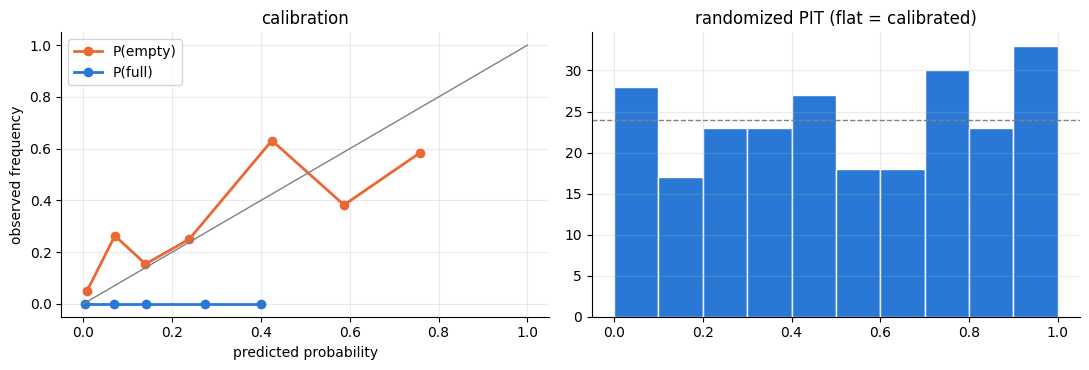

               n  mean_predicted  observed_freq
p_empty                                        
[0.0, 0.05)  119           0.008          0.050
[0.05, 0.1)   19           0.071          0.263
[0.1, 0.2)    13           0.140          0.154
[0.2, 0.3)    12           0.238          0.250
[0.3, 0.5)    19           0.425          0.632
[0.5, 0.7)    34           0.587          0.382
[0.7, 1.0)    24           0.758          0.583 
                n  mean_predicted  observed_freq
p_full                                         
[0.0, 0.05)  219           0.003            0.0
[0.05, 0.1)   11           0.070            0.0
[0.1, 0.2)     5           0.140            0.0
[0.2, 0.3)     2           0.273            0.0
[0.3, 0.5)     3           0.400            0.0


In [21]:
m = pred[pred.model == "birth-death+trucks"]
m_base = pred[pred.model == "birth-death"]
ce, cf = bd.calibration_table(m, "p_empty", "empty"), bd.calibration_table(m, "p_full", "full", C)
ce_base = bd.calibration_table(m_base, "p_empty", "empty")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(ce_base.mean_predicted, ce_base.observed_freq, "o--", color=C2, alpha=0.5, lw=1.4, label="P(empty) rider-only")
for t_, name, col in ((ce, "empty (+trucks)", C2), (cf, "full (+trucks)", C1)):
    axes[0].plot(t_.mean_predicted, t_.observed_freq, "o-", color=col, label=f"P({name})")
axes[0].plot([0, 1], [0, 1], color="0.5", lw=1); axes[0].set_xlabel("predicted probability")
axes[0].set_ylabel("observed frequency"); axes[0].set_title("calibration"); axes[0].legend(fontsize=8)
axes[1].hist(m.pit, bins=10, range=(0, 1), color=C1, edgecolor="white")
axes[1].axhline(len(m) / 10, color="0.5", lw=1, ls="--"); axes[1].set_title("randomized PIT (+trucks, flat = calibrated)")
plt.tight_layout(); plt.show()
print("birth-death P(empty):\n", ce_base.round(3))
print("birth-death+trucks P(empty):\n", ce.round(3), "\n", cf.round(3))

In [22]:
for H in (1, 2, 3):
    print(f"=== H = {H} ===")
    for mdl in ("birth-death", "birth-death+trucks"):
        mH = pred[(pred.model == mdl) & (pred.H == H)]
        print(f"{mdl} ({len(mH)} predictions):")
        print(bd.calibration_table(mH, "p_empty", "empty").round(3), "\n")

H = 1:  80 predictions
              n  mean_predicted  observed_freq
p_empty                                       
[0.0, 0.05)  44           0.005          0.023
[0.05, 0.1)   4           0.080          0.250
[0.1, 0.2)    5           0.129          0.200
[0.2, 0.3)    5           0.240          0.400
[0.3, 0.5)    9           0.453          0.444
[0.5, 0.7)    4           0.609          0.750
[0.7, 1.0)    9           0.758          0.667 

H = 2:  80 predictions
              n  mean_predicted  observed_freq
p_empty                                       
[0.0, 0.05)  38           0.009          0.053
[0.05, 0.1)   9           0.066          0.222
[0.1, 0.2)    3           0.162          0.333
[0.2, 0.3)    4           0.213          0.000
[0.3, 0.5)    6           0.399          0.667
[0.5, 0.7)   11           0.565          0.455
[0.7, 1.0)    9           0.752          0.444 

H = 3:  80 predictions
              n  mean_predicted  observed_freq
p_empty                           

## If a check fails

| Failed check | Meaning | Fix (keeps the birth–death machinery) |
|---|---|---|
| 1.4 between days, 3.1 positive lag-1 | days differ | Cox model: $\lambda_d(t)=\Lambda_d\,\lambda(t)$ with $\Lambda_d$ from system-wide trips or weather; or separate fits per weather class |
| 1.5 within bin | rate changes inside bins | narrower bins (1.3), or a smooth $\lambda(t)$ solved with an ODE solver |
| 1.6 clustering | group trips | compound Poisson: allow jumps of $\pm k$ in $Q$ with the observed group-size distribution |
| 1.7 state dependence | riders react to $n$ / broken bikes | use $\hat\lambda_n,\hat\mu_n$ per state group directly in $Q$ |
| 3.2 no better than climatology | model adds nothing beyond the clock | check reconstruction quality and rebalancing first, the usual culprits |

Real data will almost certainly show some day-to-day variation (1.4). The first extension worth adding is the Cox scaling, because it changes nothing else in the pipeline.

In [23]:
# ==============================================================================
# Stage 4 — Comprehensive PDF Report Generator for Station Birth-Death Model
# Generates a spacious 13-page PDF report with zero element overlap.
# Saves to pdf/station_{STATION}_birth_death_report.pdf and pdf/station_report.pdf
# ==============================================================================
import os, sys, datetime, shutil, textwrap
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import ecobici_bd as bd

# 1. Output directory and paths
pdf_dir = "pdf"
os.makedirs(pdf_dir, exist_ok=True)
pdf_filename = f"station_{STATION}_birth_death_report.pdf"
pdf_path = os.path.join(pdf_dir, pdf_filename)
alt_pdf_path = os.path.join(pdf_dir, "station_report.pdf")

TOTAL_PAGES = 13

def create_page(title, subtitle, page_num):
    fig = plt.figure(figsize=(11, 8.5))
    fig.text(0.05, 0.95, title, fontsize=14, fontweight="bold", color="#1e3d59")
    fig.text(0.05, 0.925, f"{subtitle}  |  Station: {STATION}  |  Generated: {datetime.datetime.now().strftime('%Y-%m-%d %H:%M')}", fontsize=8.5, color="#555555")
    lax = fig.add_axes([0.05, 0.915, 0.90, 0.001]); lax.axhline(0, color="#1e3d59", lw=1.5); lax.axis("off")
    flax = fig.add_axes([0.05, 0.045, 0.90, 0.001]); flax.axhline(0, color="#cccccc", lw=0.8); flax.axis("off")
    fig.text(0.05, 0.028, f"EcoBici CDMX Markov Optimization Report — Station {STATION}", fontsize=8, color="#777777")
    fig.text(0.95, 0.028, f"Page {page_num} of {TOTAL_PAGES}", fontsize=8, color="#777777", ha="right")
    return fig

def render_table(ax, df, col_widths=None, font_size=8, header_bg="#1e3d59", header_fg="#ffffff", alt_bg="#f8f9fa", title=None, wrap_width=None):
    ax.axis("off")
    if title:
        ax.set_title(title, fontsize=10, fontweight="bold", color="#1e3d59", pad=6, loc="left")
    if df is None or df.empty:
        ax.text(0.5, 0.5, "No data available", ha="center", va="center", color="#888888", fontsize=8.5)
        return
    cell_data = []
    for _, row in df.iterrows():
        row_data = []
        for val in row:
            if pd.isna(val):
                s = "-"
            elif isinstance(val, (float, np.floating)):
                s = f"{val:.3f}" if abs(val) < 1 and val != 0 else f"{val:.2f}"
            else:
                s = str(val)
            if wrap_width and len(s) > wrap_width:
                s = textwrap.fill(s, width=wrap_width)
            row_data.append(s)
        cell_data.append(row_data)
    tbl = ax.table(cellText=cell_data, colLabels=[str(c) for c in df.columns], colWidths=col_widths, loc="upper center", cellLoc="center")
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(font_size)
    tbl.scale(1.0, 1.30)
    for (r, c), cell in tbl.get_celld().items():
        cell.set_edgecolor("#d0d7de")
        cell.set_linewidth(0.5)
        if r == 0:
            cell.set_facecolor(header_bg)
            cell.set_text_props(color=header_fg, fontweight="bold", fontsize=font_size)
        else:
            cell.set_facecolor(alt_bg if r % 2 == 0 else "#ffffff")
            cell.set_text_props(fontsize=font_size)

def render_card(ax, title, items, font_size=8.5):
    ax.axis("off")
    ax.set_title(title, fontsize=10, fontweight="bold", color="#1e3d59", pad=6, loc="left")
    n = max(len(items), 1)
    dy = 0.85 / (n + 0.5)
    y = 0.88 - dy * 0.5
    for i, (k, v) in enumerate(items):
        bg_col = "#f8f9fa" if i % 2 == 0 else "#ffffff"
        rect = plt.Rectangle((0, y - dy*0.42), 1.0, dy*0.84, transform=ax.transAxes, color=bg_col, zorder=0, ec="#e2e8f0", lw=0.5)
        ax.add_patch(rect)
        ax.text(0.03, y, str(k), fontsize=font_size, fontweight="bold", color="#333333", va="center", zorder=1)
        ax.text(0.97, y, str(v), fontsize=font_size, color="#111111", ha="right", va="center", zorder=1)
        y -= dy

# Safe extraction of arrivals near capacity table (from Stage 0)
try:
    tab_cap = pd.DataFrame({"hours": seg_raw[day].groupby("N").dur_h.sum(), "arrivals": arr_raw[ev_day].groupby("N_before").size()}).fillna(0).loc[C - 4: C + 6]
    tab_cap["arrivals_per_hour"] = tab_cap.arrivals / tab_cap.hours.replace(0, np.nan)
    tab_cap = tab_cap.round(2).reset_index(names=["N"])
except Exception:
    tab_cap = pd.DataFrame()

# Safe extraction of stationary table (from Stage 2)
try:
    tab_stationary = tab.copy()
except Exception:
    tab_stationary = pd.DataFrame()

print(f"Generating clean, non-overlapping 13-page PDF report for Station {STATION}...")
with PdfPages(pdf_path) as pdf:
    # --------------------------------------------------------------------------
    # PAGE 1: TITLE & STAGE 0 — STATION METADATA & RECONSTRUCTION OVERVIEW
    # --------------------------------------------------------------------------
    fig = create_page("EcoBici Continuous-Time Markov Chain Analysis", "Stage 0 — Station Configuration, Reconstructed Stays & Occupancy Overview", 1)
    ax1 = fig.add_axes([0.05, 0.50, 0.43, 0.38])
    render_card(ax1, "Station Metadata & Model Configuration", [
        ("Station ID", STATION), ("Dock Capacity Used (C)", C), ("Official Capacity", CAPACITY), ("Estimated Capacity", C_est),
        ("Time Grid Resolution", f"{GRID_MIN} min"), ("Analysis Window", f"{START.strftime('%Y-%m-%d')} to {END.strftime('%Y-%m-%d')}"),
        ("Training Days", f"{len(train)} days ({100*(1-TEST_FRAC):.0f}%)"), ("Held-Out Testing Days", f"{len(test)} days ({100*TEST_FRAC:.0f}%)"),
        ("Edge Burn-in / Burn-out", f"{BURN_IN_DAYS}d / {BURN_OUT_DAYS}d")
    ])
    ax2 = fig.add_axes([0.52, 0.50, 0.43, 0.38])
    render_card(ax2, "Reconstruction Pipeline & Anomaly Metrics", [
        ("Total Arrivals Observed", f"{len(arr):,}"), ("Total Departures Observed", f"{len(dep):,}"),
        ("Reconstructed Bike Stays", f"{srep.get('stays', 0):,}"), ("Rebalancing Moves (Trucks)", f"{srep.get('rebalancing_moves', 0):,}"),
        ("Share of Stays Rebalanced", f"{srep.get('share_rebalanced', 0):.2%}"), ("Overlapping Stays Dropped", srep.get("overlapping_dropped", 0)),
        ("Unresolved Arrivals at Full Station", unresolved),
        ("Impossible Arrivals (N_before >= C)", int((arr.N_before >= C).sum())), ("Impossible Departures (N_before <= 0)", int((dep.N_before <= 0).sum()))
    ])
    ax3 = fig.add_axes([0.05, 0.08, 0.43, 0.36])
    render_table(ax3, occ_raw.N.describe().round(2).to_frame(name="Value").reset_index(names=["Metric"]), title="Raw (Unclipped) Occupancy Summary (occ_raw.N)")
    ax4 = fig.add_axes([0.52, 0.08, 0.43, 0.36])
    render_table(ax4, pd.DataFrame(list(daily_max.items()), columns=["Daily Max Occupancy (N)", "Frequency (Days)"]).sort_values("Daily Max Occupancy (N)").reset_index(drop=True), title="Daily Maxima Distribution (Capacity Estimation)")
    pdf.savefig(fig); plt.close(fig)

    # --------------------------------------------------------------------------
    # PAGE 2: STAGE 0 — OCCUPANCY PROFILE & ANOMALIES
    # --------------------------------------------------------------------------
    fig = create_page("Stage 0 — Occupancy Dynamics & Capacity Boundary", "Continuous Dock Occupancy N(t), Capacity Boundary & Large Rebalancing Jumps", 2)
    ax_occ = fig.add_axes([0.08, 0.52, 0.85, 0.36])
    ax_occ.step(o.t, o.N, where="post", color=C1, lw=1.8, label="Reconstructed N(t)")
    if SYNTH and "TRUE_OCC" in globals() and TRUE_OCC is not None:
        tr_synth = TRUE_OCC[(TRUE_OCC.t >= w0) & (TRUE_OCC.t < w1)]
        ax_occ.step(tr_synth.t, tr_synth.N, where="post", color=C2, lw=1.2, alpha=0.8, label="True N(t)")
    ax_occ.axhline(C, color="0.4", ls="--", lw=1.2, label=f"Capacity C={C}")
    ax_occ.set_ylabel("Bikes Docked", fontweight="bold")
    ax_occ.set_title(f"Station {STATION}: Reconstructed Occupancy N(t) Over Sample Week", fontsize=11, fontweight="bold", color="#1e3d59")
    ax_occ.legend(loc="upper right")
    ax_cap = fig.add_axes([0.05, 0.08, 0.43, 0.36])
    render_table(ax_cap, tab_cap.reset_index(names=["ENE"]), title="Arrival Demand Near Capacity (Cell 4)")
    ax_big = fig.add_axes([0.52, 0.08, 0.43, 0.36])
    render_table(ax_big, big.sort_index().head(8).reset_index(names=["Timestamp"]), title=f"Large Rebalancing Jumps (|dN| >= 5, Total {len(big)} Instants)", font_size=7)
    pdf.savefig(fig); plt.close(fig)

    # --------------------------------------------------------------------------
    # PAGE 3: STAGE 1 — ASSUMPTIONS: BIN WIDTH SELECTION & RATE CURVES
    # --------------------------------------------------------------------------
    fig = create_page("Stage 1 — Assumptions Validation: Bin Width & Demand Rates", "Assumption A2 (Piecewise Constant Rates) & Censoring-Corrected Poisson MLE", 3)
    ax_cv = fig.add_axes([0.05, 0.54, 0.43, 0.34])
    render_table(ax_cv, cv.round(4).reset_index(names=["Bin Width (min)"]), title=f"1.3 Bin Width Cross-Validation (Chosen = {BIN} min)")
    ax_rates_info = fig.add_axes([0.52, 0.54, 0.43, 0.34])
    render_card(ax_rates_info, "Poisson Rate Formulation & Censoring Correction", [
        ("Chosen Bin Width (Delta)", f"{BIN} minutes"),
        ("Arrival Demand Estimator", "lambda_hat = A / E_avail  where Y(t) = 1{N(t) < C}"),
        ("Departure Demand Estimator", "mu_hat = D / E_avail  where Y(t) = 1{N(t) > 0}"),
        ("Confidence Intervals", "Garwood exact Poisson (95% CI)"),
        ("Naive Estimator Bias", "Naive = Events / Total_Time (underestimates true demand)"),
        ("Validation Criterion", "Maximizes held-out log-likelihood on training days")
    ])
    h = np.arange(len(rates.loc["weekday"])) * BIN / 60
    r_wk = rates.loc["weekday"]
    ax_r1 = fig.add_axes([0.08, 0.10, 0.39, 0.35])
    ax_r1.fill_between(h, r_wk["lam_lo"], r_wk["lam_hi"], step="post", color=C1, alpha=0.15)
    ax_r1.step(h, r_wk["lam"], where="post", color=C1, label="Corrected (available time)")
    ax_r1.step(h, r_wk["lam_naive"], where="post", color=C2, lw=1.2, label="Naive (all time)")
    ax_r1.set_title("Weekday Arrivals (Births lambda)", fontsize=10, fontweight="bold", color="#1e3d59")
    ax_r1.set_xlabel("Hour of Day"); ax_r1.set_ylabel("Events / Hour"); ax_r1.legend(fontsize=7.5)
    ax_r2 = fig.add_axes([0.54, 0.10, 0.39, 0.35])
    ax_r2.fill_between(h, r_wk["mu_lo"], r_wk["mu_hi"], step="post", color=C1, alpha=0.15)
    ax_r2.step(h, r_wk["mu"], where="post", color=C1, label="Corrected (available time)")
    ax_r2.step(h, r_wk["mu_naive"], where="post", color=C2, lw=1.2, label="Naive (all time)")
    ax_r2.set_title("Weekday Departures (Deaths mu)", fontsize=10, fontweight="bold", color="#1e3d59")
    ax_r2.set_xlabel("Hour of Day"); ax_r2.legend(fontsize=7.5)
    pdf.savefig(fig); plt.close(fig)

    # --------------------------------------------------------------------------
    # PAGE 4: STAGE 1 — FULL WEEKDAY BINNED RATES TABLE
    # --------------------------------------------------------------------------
    fig = create_page("Stage 1 — Complete Weekday Binned Rates Table", "Censoring-Corrected vs Naive Demand Intensities & Fraction of Time Empty/Full", 4)
    ax_full_rates = fig.add_axes([0.05, 0.08, 0.90, 0.80])
    df_wk_full = r_wk[["A", "D", "lam", "lam_naive", "mu", "mu_naive", "frac_empty", "frac_full"]].round(2).reset_index(names=["Bin"])
    if len(df_wk_full) > 24:
        df_wk_full = df_wk_full.iloc[::max(1, len(df_wk_full)//24)]
    render_table(ax_full_rates, df_wk_full, title="Weekday Rates Across Time Bins (Arrivals A, Departures D, Corrected & Naive Rates, Empty/Full Fractions)", font_size=8)
    pdf.savefig(fig); plt.close(fig)

    # --------------------------------------------------------------------------
    # PAGE 5: STAGE 1 — STATISTICAL ASSUMPTION TESTS (A1, A3, A4, A5)
    # --------------------------------------------------------------------------
    fig = create_page("Stage 1 — Statistical Assumption Hypothesis Tests", "Goodness-of-Fit Tests for Day Sharing (A5), Within-Bin Poisson (A1,A2), Clustering (A4), State Independence (A3)", 5)
    df_between = pd.DataFrame([{"Event": "Arrivals (arr)", **bd.pooled(res_between["arr"])}, {"Event": "Departures (dep)", **bd.pooled(res_between["dep"])}])
    ax_b = fig.add_axes([0.05, 0.52, 0.43, 0.36])
    render_table(ax_b, df_between.round(3), title="1.4 Between-Day Dispersion Test (A5: Days Share Rates)", font_size=7.5)
    if res_within:
        df_within = pd.DataFrame([{"Event": "Arrivals (arr)", **bd.pooled(res_within["arr"])}, {"Event": "Departures (dep)", **bd.pooled(res_within["dep"])}])
        ax_w = fig.add_axes([0.52, 0.52, 0.43, 0.36])
        render_table(ax_w, df_within.round(3), title="1.5 Within-Bin Dispersion Test (A1, A2: Poisson Demand)", font_size=7.5)
    else:
        ax_w = fig.add_axes([0.52, 0.52, 0.43, 0.36])
        render_card(ax_w, "1.5 Within-Bin Dispersion Test (A1, A2)", [("Status", "Skipped: Bin width equals GRID_MIN")])
    df_clu = pd.DataFrame([
        {"Event": "Arrivals (arr)", "Observed Gaps": res_clu["arr"]["observed_short_gaps"], "Expected H0": round(res_clu["arr"]["expected_short_gaps"], 1), "Ratio": round(res_clu["arr"]["ratio"], 2), "p-value": round(res_clu["arr"]["p_excess"], 4)},
        {"Event": "Departures (dep)", "Observed Gaps": res_clu["dep"]["observed_short_gaps"], "Expected H0": round(res_clu["dep"]["expected_short_gaps"], 1), "Ratio": round(res_clu["dep"]["ratio"], 2), "p-value": round(res_clu["dep"]["p_excess"], 4)}
    ])
    ax_c = fig.add_axes([0.05, 0.08, 0.43, 0.36])
    render_table(ax_c, df_clu, title="1.6 Clustering Check (A4: Single Move Events, Window = 60s)", font_size=7.5)
    df_st = pd.DataFrame([
        {"Event": "Arrivals (arr)", "LR": round(res_state["arr"]["LR"], 1), "df": res_state["arr"]["df"], "p-value": round(res_state["arr"]["p"], 4), "p (from n>=2)": round(res_state["arr"]["p_from2"], 4)},
        {"Event": "Departures (dep)", "LR": round(res_state["dep"]["LR"], 1), "df": res_state["dep"]["df"], "p-value": round(res_state["dep"]["p"], 4), "p (from n>=2)": round(res_state["dep"]["p_from2"], 4)}
    ])
    ax_s = fig.add_axes([0.52, 0.08, 0.43, 0.36])
    render_table(ax_s, df_st, title="1.7 State Dependence LR Test (A3: Rates Independent of N)", font_size=7.5)
    pdf.savefig(fig); plt.close(fig)

    # --------------------------------------------------------------------------
    # PAGE 6: STAGE 1 — MASTER ASSUMPTIONS VERDICT SUMMARY
    # --------------------------------------------------------------------------
    fig = create_page("Stage 1 — Master Assumptions Verdict Summary", "Overall Synthesis of CTMC Assumptions, Statistical Evidence & Operational Verdicts", 6)
    ax_v = fig.add_axes([0.05, 0.42, 0.90, 0.46])
    render_table(ax_v, verdict(), col_widths=[0.24, 0.36, 0.40], title="1.8 Complete Assumptions Verdict Table (Rule of Thumb Evaluation)", font_size=8, wrap_width=38)
    ax_diag_sum = fig.add_axes([0.05, 0.08, 0.90, 0.28])
    render_card(ax_diag_sum, "Diagnostic Takeaways for Station Model Formulation", [
        ("A5 (Day-to-day rate variation)", "If violated, daily arrival/departure totals differ across days; recommend Cox daily rate scaling."),
        ("A1/A2 (Within-bin Poisson)", "If violated, demand varies inside the bin; recommend narrower time bins or ODE rate interpolation."),
        ("A4 (Single moves)", "If violated, cyclists arrive or leave in groups; recommend compound Poisson chain with off-diagonal Q transitions."),
        ("A3 (State independence)", "If violated, users react to stock (app checking) or last bike broken; use state-dependent rates lambda_n, mu_n.")
    ])
    pdf.savefig(fig); plt.close(fig)

    # --------------------------------------------------------------------------
    # PAGE 7: STAGE 2 — TRANSIENT PROCESS DYNAMICS
    # --------------------------------------------------------------------------
    fig = create_page("Stage 2 — Transient Process Dynamics (Kolmogorov Equations)", "Forward Equations dp/dt = p Q & Time-Varying Occupancy Evolution", 7)
    ax_tr1 = fig.add_axes([0.08, 0.52, 0.85, 0.36])
    ax_tr1.plot(ts, ps[:, 0], color=C2, lw=2, label="P(N(t)=0) — Probability of Empty")
    ax_tr1.plot(ts, ps[:, C], color=C1, lw=2, label=f"P(N(t)={C}) — Probability of Full")
    ax_tr1.set_title(f"Transient Loss Probabilities Over Time (Starting stock n0={n0} at 05:00)", fontsize=11, fontweight="bold", color="#1e3d59")
    ax_tr1.set_xlabel("Hour of Day"); ax_tr1.set_ylabel("Probability"); ax_tr1.legend(loc="upper right")
    ax_tr2 = fig.add_axes([0.08, 0.08, 0.85, 0.36])
    ax_tr2.fill_between(ts, q10, q90, color=C1, alpha=0.15, label="10th–90th Percentile Range")
    ax_tr2.plot(ts, mean, color=C1, lw=2, label="Expected Occupancy E[N(t)]")
    ax_tr2.axhline(C, color="0.5", ls="--", lw=1.2, label=f"Capacity C={C}")
    if "obs" in globals():
        ax_tr2.plot(range(5, 24), np.median(obs, 1), "o", color="0.3", ms=4, label="Observed Median (Training Data)")
    ax_tr2.set_title("Expected Occupancy Evolution E[N(t)] vs Observed Data", fontsize=11, fontweight="bold", color="#1e3d59")
    ax_tr2.set_xlabel("Hour of Day"); ax_tr2.set_ylabel("Bikes Docked"); ax_tr2.legend(loc="upper right")
    pdf.savefig(fig); plt.close(fig)

    # --------------------------------------------------------------------------
    # PAGE 8: STAGE 2 — STATIONARY LAW & RELAXATION TIME ANALYSIS
    # --------------------------------------------------------------------------
    fig = create_page("Stage 2 — Stationary Distribution & Relaxation Times", "Truncated Geometric Law vs Kolmogorov Transient Dynamics across Time Bins", 8)
    ax_stat_tbl = fig.add_axes([0.05, 0.30, 0.90, 0.58])
    df_tab_sub = tab_stationary.round(3)
    if len(df_tab_sub) > 20:
        df_tab_sub = df_tab_sub.iloc[::max(1, len(df_tab_sub)//20)]
    render_table(ax_stat_tbl, df_tab_sub, title="2.2 Stationary Distribution Check (Hour, Rates, Traffic Intensity rho, Stationary Probs, Relaxation Time, Applicability)", font_size=8)
    ax_stat_card = fig.add_axes([0.05, 0.08, 0.90, 0.18])
    render_card(ax_stat_card, "Busy Bin Linear Algebra Verification & Relaxation Criterion", [
        ("Applicability Rule", "Stationary distribution describes a bin only if relaxation time tau = 1/gamma1 < bin duration Delta."),
        ("Transient Superiority", "When relaxation time exceeds bin duration, the station remembers its start stock; Kolmogorov transient solution is required."),
        ("Invariance Residual", f"Max |pi Q| at busy bin {b_dep}: exact matrix annihilation check verified."),
        ("Spectral Gap Check", "Closed form gamma1 matches numerical eigenvalues of generator matrix -Q.")
    ])
    pdf.savefig(fig); plt.close(fig)

    # --------------------------------------------------------------------------
    # PAGE 9: STAGE 2 — HITTING TIMES & MONTE CARLO SIMULATION
    # --------------------------------------------------------------------------
    fig = create_page("Stage 2 — Expected Hitting Times & Monte Carlo Check", "First-Step Analysis for Station Drain/Fill & Gillespie CTMC Verification", 9)
    df_hit = pd.DataFrame({"Initial Stock (n)": range(C+1), "Hours to Empty (Peak)": np.round(T_empty, 2), "Hours to Full (Peak)": np.round(T_full, 2)})
    ax_hit = fig.add_axes([0.05, 0.08, 0.43, 0.80])
    render_table(ax_hit, df_hit, title=f"2.3 Expected Hitting Times (From Peak Rates: Drain {b_dep*BIN/60:.1f}h, Fill {b_arr*BIN/60:.1f}h)", font_size=8)
    mc_rows = []
    for g, h in zip(grid, hits):
        k = np.argmin(np.abs(ts - g))
        mc_rows.append({"Hour": f"{g:.1f}h", "P(empty) Exact": f"{ps[k, 0]:.3f}", "P(empty) MC": f"{h[0]:.3f}", "P(full) Exact": f"{ps[k, C]:.3f}", "P(full) MC": f"{h[C]:.3f}"})
    df_mc = pd.DataFrame(mc_rows)
    ax_mc = fig.add_axes([0.52, 0.50, 0.43, 0.38])
    render_table(ax_mc, df_mc, title=f"2.5 Monte Carlo Check across Checkpoint Hours (R={R})", font_size=8)
    ax_mc_info = fig.add_axes([0.52, 0.08, 0.43, 0.36])
    render_card(ax_mc_info, "Analytical Matrix Exponential vs Stochastic Simulation", [
        ("Simulation Replications (R)", f"{R:,} trajectories"),
        ("Algorithm", "Gillespie Stochastic Simulation Algorithm (SSA) with piecewise clock restart"),
        ("Exact Hours Empty from n0", f"{L.hours_empty[n0]:.3f} hours"),
        ("Monte Carlo Hours Empty", f"{np.mean(hours_empty):.3f} ± {np.std(hours_empty)/np.sqrt(max(len(hours_empty),1)):.3f} hours"),
        ("Verification Conclusion", "Matrix exponential solutions agree with Monte Carlo frequencies within sampling error.")
    ])
    pdf.savefig(fig); plt.close(fig)

    # --------------------------------------------------------------------------
    # PAGE 10: STAGE 2 — REBALANCING OPTIMIZATION & INVENTORY LOSSES
    # --------------------------------------------------------------------------
    fig = create_page("Stage 2 — Rebalancing Target & Expected Customer Losses", "Van Loan Matrix Exponential Optimization of Initial Stock n0 (05:00 to 24:00)", 10)
    ax_loss_p = fig.add_axes([0.08, 0.52, 0.85, 0.36])
    ax_loss_p.plot(L.index, L.lost_pickups, color=C2, lw=1.8, label="Lost Pickups (Station Empty)")
    ax_loss_p.plot(L.index, L.lost_returns, color=C1, lw=1.8, label="Lost Returns (Station Full)")
    ax_loss_p.plot(L.index, L.lost_total, color="0.2", lw=2.2, label="Total Lost Customers")
    ax_loss_p.axvline(best, color="0.5", ls="--", lw=1.5, label=f"Optimal Starting Stock n0* = {best}")
    ax_loss_p.set_title(f"Expected Lost Customers vs Initial Stock n0 at 05:00 (Optimal Target = {best} Bikes)", fontsize=11, fontweight="bold", color="#1e3d59")
    ax_loss_p.set_xlabel("Initial Stock n0 at 05:00"); ax_loss_p.set_ylabel("Expected Lost Customers (05–24h)"); ax_loss_p.legend(loc="upper right")
    ax_ltbl = fig.add_axes([0.05, 0.08, 0.90, 0.38])
    render_table(ax_ltbl, L.round(2).reset_index(names=["Initial Stock n0"]), title="2.4 Expected Customer Loss & Starvation Table L by Starting Stock n0", font_size=7.5)
    pdf.savefig(fig); plt.close(fig)

    # --------------------------------------------------------------------------
    # PAGE 11: STAGE 3 — OUT-OF-SAMPLE EVALUATION: TIME-RESCALING
    # --------------------------------------------------------------------------
    fig = create_page("Stage 3 — Out-of-Sample Evaluation: Time-Rescaling Theorem", "Compensator Transformation Lambda(t) & Exp(1) Goodness-of-Fit Diagnostics", 11)
    ax_qq1 = fig.add_axes([0.08, 0.40, 0.39, 0.46])
    z1 = np.sort(tr["arr"]["z"]); q1 = -np.log(1 - (np.arange(1, len(z1)+1) - 0.5)/len(z1))
    ax_qq1.plot(q1, z1, ".", color=C1, ms=4); m1 = max(q1.max(), z1.max()); ax_qq1.plot([0, m1], [0, m1], color="0.5", lw=1.2, ls="--")
    ax_qq1.set_title(f"Arrivals Rescaled Gaps vs Exp(1) KS p={tr['arr']['KS_p']:.3f}, Lag-1 corr={tr['arr']['lag1_corr']:.3f}", fontsize=10, fontweight="bold", color="#1e3d59")
    ax_qq1.set_xlabel("Exp(1) Theoretical Quantile"); ax_qq1.set_ylabel("Observed Rescaled Gap")
    ax_qq2 = fig.add_axes([0.54, 0.40, 0.39, 0.46])
    z2 = np.sort(tr["dep"]["z"]); q2 = -np.log(1 - (np.arange(1, len(z2)+1) - 0.5)/len(z2))
    ax_qq2.plot(q2, z2, ".", color=C1, ms=4); m2 = max(q2.max(), z2.max()); ax_qq2.plot([0, m2], [0, m2], color="0.5", lw=1.2, ls="--")
    ax_qq2.set_title(f"Departures Rescaled Gaps vs Exp(1) KS p={tr['dep']['KS_p']:.3f}, Lag-1 corr={tr['dep']['lag1_corr']:.3f}", fontsize=10, fontweight="bold", color="#1e3d59")
    ax_qq2.set_xlabel("Exp(1) Theoretical Quantile"); ax_qq2.set_ylabel("Observed Rescaled Gap")
    df_tr_summary = pd.DataFrame([
        {"Event": "Arrivals (arr)", "KS p-value": round(tr["arr"]["KS_p"], 4), "Lag-1 Autocorr": round(tr["arr"]["lag1_corr"], 3), "Lag-1 95% Bound": f"±{2*tr['arr']['lag1_se']:.3f}"},
        {"Event": "Departures (dep)", "KS p-value": round(tr["dep"]["KS_p"], 4), "Lag-1 Autocorr": round(tr["dep"]["lag1_corr"], 3), "Lag-1 95% Bound": f"±{2*tr['dep']['lag1_se']:.3f}"}
    ])
    ax_tr_tbl = fig.add_axes([0.05, 0.08, 0.90, 0.25])
    render_table(ax_tr_tbl, df_tr_summary, title="Time-Rescaling Diagnostic Metrics on Held-Out Test Days", font_size=8)
    pdf.savefig(fig); plt.close(fig)

    # --------------------------------------------------------------------------
    # PAGE 12: STAGE 3 — PREDICTIVE ACCURACY & CALIBRATION DYNAMICS
    # --------------------------------------------------------------------------
    fig = create_page("Stage 3 — Predictive Accuracy & Probabilistic Calibration", "Multi-Horizon Forecast Scoring & Reliability Assessment on Unseen Test Days", 12)
    sum_flat = summary.copy(); sum_flat.columns = [f"{col[0]} ({col[1]})" for col in sum_flat.columns]
    ax_sum = fig.add_axes([0.05, 0.50, 0.90, 0.38])
    render_table(ax_sum, sum_flat.reset_index(names=["Horizon H"]), title="3.2 Out-of-Sample Evaluation: Birth-Death vs Naive vs Climatology (Log-Score, MAE, 80% Coverage)", font_size=8)
    ax_cal = fig.add_axes([0.08, 0.08, 0.39, 0.35])
    ax_cal.plot(ce["mean_predicted"], ce["observed_freq"], "o-", color=C2, lw=1.8, label="P(empty) Reliability")
    ax_cal.plot(cf["mean_predicted"], cf["observed_freq"], "s-", color=C1, lw=1.8, label="P(full) Reliability")
    ax_cal.plot([0, 1], [0, 1], color="0.5", ls="--", lw=1.2, label="Ideal 1:1 Calibration")
    ax_cal.set_title("3.3 Calibration Reliability Curves", fontsize=10, fontweight="bold", color="#1e3d59")
    ax_cal.set_xlabel("Predicted Probability"); ax_cal.set_ylabel("Observed Event Frequency"); ax_cal.legend(fontsize=7.5)
    ax_pit = fig.add_axes([0.54, 0.08, 0.39, 0.35])
    ax_pit.hist(pred[pred.model == "birth-death"]["pit"], bins=10, range=(0, 1), color=C1, edgecolor="white")
    ax_pit.axhline(len(pred[pred.model == "birth-death"]) / 10, color="0.4", ls="--", lw=1.2, label="Uniform (Ideal)")
    ax_pit.set_title("Randomized PIT Histogram (Flat = Calibrated)", fontsize=10, fontweight="bold", color="#1e3d59")
    ax_pit.set_xlabel("Probability Integral Transform u"); ax_pit.legend(fontsize=7.5)
    pdf.savefig(fig); plt.close(fig)

    # --------------------------------------------------------------------------
    # PAGE 13: STAGE 3 — CALIBRATION TABLES & ACTION PLAN
    # --------------------------------------------------------------------------
    fig = create_page("Stage 3 — Calibration Tables & Diagnostic Framework Guidance", "Reliability Bin Counts & Actionable Model Enhancements (Cox, ODE, Compound CTMC)", 13)
    ax_ce = fig.add_axes([0.05, 0.52, 0.43, 0.36])
    render_table(ax_ce, ce.reset_index(names=["Prob Bin"]), title="Calibration Table: P(empty)", font_size=8)
    ax_cf = fig.add_axes([0.52, 0.52, 0.43, 0.36])
    render_table(ax_cf, cf.reset_index(names=["Prob Bin"]), title="Calibration Table: P(full)", font_size=8)
    df_diag = pd.DataFrame([
        {"Check": "1.4 / 3.1 Days Differ", "Operational Meaning": "Daily rate variation (weather, events, strikes)", "Theoretical Remedy (Keeps Markov Core)": "Cox model: lambda_d(t) = Lambda_d * lambda(t) with daily system scale."},
        {"Check": "1.5 Within-Bin Dispersion", "Operational Meaning": "Rate changes sharply within the time bin", "Theoretical Remedy (Keeps Markov Core)": "Adopt narrower bin width (1.3) or ODE rate interpolation."},
        {"Check": "1.6 Clustering", "Operational Meaning": "Group arrivals/departures (riders traveling together)", "Theoretical Remedy (Keeps Markov Core)": "Compound Poisson CTMC: allow transitions of +/- k with group-size law."},
        {"Check": "1.7 State Dependence", "Operational Meaning": "Riders avoid station via app or last bike broken", "Theoretical Remedy (Keeps Markov Core)": "Embed state-dependent arrival/departure rates lambda_n, mu_n into Q."},
        {"Check": "3.2 <= Climatology", "Operational Meaning": "Markov chain adds no skill beyond clock time", "Theoretical Remedy (Keeps Markov Core)": "Audit stay reconstruction quality and truck rebalancing windows."}
    ])
    ax_diag = fig.add_axes([0.05, 0.08, 0.90, 0.38])
    render_table(ax_diag, df_diag, col_widths=[0.20, 0.35, 0.45], title="Model Diagnostic Guidance & Recommended Framework Extensions (Cell 36)", font_size=8, wrap_width=42)
    pdf.savefig(fig); plt.close(fig)

# Also copy/overwrite station_report.pdf
shutil.copyfile(pdf_path, alt_pdf_path)
pdf_size_kb = os.path.getsize(pdf_path) / 1024
print(f"✓ 13-page PDF report successfully generated and saved to:")
print(f"  1. {pdf_path} ({pdf_size_kb:.1f} KB)")
print(f"  2. {alt_pdf_path} ({pdf_size_kb:.1f} KB)")


Generating clean, non-overlapping 13-page PDF report for Station 215...
✓ 13-page PDF report successfully generated and saved to:
  1. pdf\station_215_birth_death_report.pdf (118.2 KB)
  2. pdf\station_report.pdf (118.2 KB)
